In [49]:
import numpy as np
import matplotlib.pyplot as plt

In [50]:
def regula_falsi(f, x0, x1, tol=0.5e-5, max_iter=100):
  """
  Implements the Regula Falsi (False Position) method to find the root of f(x)=0.

  Parameters:
    f (function): The function for which the root is to be found.
    x0 (float): The initial lower bound of the interval.
    x1 (float): The initial upper bound of the interval.
    tol (float): The tolerance for the stopping criterion.
    max_iter (int): The maximum number of iterations.

  Returns:
    root (float): The approximated root.
    error_table (list): A table of iterations, root approximations, and errors.
  """
  if f(x0)*f(x1) >= 0:
    raise ValueError("The function must have opposite signs at x0 and x1.")
  error_table = []
  for iteration in range(1, max_iter+1):
    # Compute the root approximation using the formula
    x2 = x1-(f(x1)*(x1-x0))/(f(x1)-f(x0))
    error = abs(x2-x1)
    # Store iteration details
    error_table.append((iteration, x2, error))
    # Check for convergence
    if error < tol or abs(f(x2)) < tol:
      return x2, error_table
    # Update the interval
    if f(x2)*f(x0) < 0:
      x1 = x2
    else:
      x0 = x2
  raise RuntimeError("Maximum iterations exceeded without convergence.")

In [51]:
# Define the functio nfor which we want to find the root and take care of initial guess
def f(x):
  # return x**2-4
  # return x**2-6*np.exp(-x)    # x^2-6exp(-x)
  return x**2-np.cos(x)       # x^2-cos(x)
  # return x**3-2*x-8

In [52]:
# Initial guesses
x0, x1 = 0, 1

In [53]:
# Find the root and generate the error table
root, error_table = regula_falsi(f, x0, x1)

In [54]:
# Print the error table
print("Iteration\tRoot Approximation\tError")
for iteration, x2, error in error_table:
  print(f"{iteration}\t{x2:.6f}\t\t{error:.6e}")

Iteration	Root Approximation	Error
1	0.685073		3.149266e-01
2	0.810694		1.893064e-01
3	0.822932		1.770684e-01
4	0.824026		1.759742e-01
5	0.824123		1.758771e-01
6	0.824131		1.758685e-01


In [55]:
# Plot the convergence
iterations = [row[0] for row in error_table]
errors = [row[2] for row in error_table]

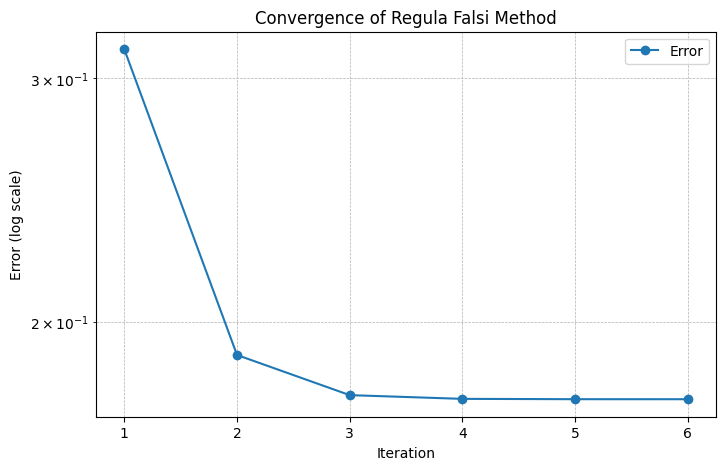

In [56]:
plt.figure(figsize=(8, 5))
plt.plot(iterations, errors, marker='o', label='Error')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Error (log scale)')
plt.title('Convergence of Regula Falsi Method')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()
plt.show()